# Milestone 1 – Netflix Data Analysis
**CIE: Data Transformation, Null Value Handling, Insight Generation, and Visualization**

## 1. Import libraries and read the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_titles.csv")
print("Dataset loaded successfully")
df.head()

Dataset loaded successfully


,index,id,title,type,description,release_year,age_certification,runtime,imdb_id,imdb_score,imdb_votes
0,0,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,113,tt0075314,8.3,795222.0
1,1,tm127384,Monty Python and the Holy Grail,MOVIE,"King Arthur, accompanied by his squire, recrui...",1975,PG,91,tt0071853,8.2,530877.0
2,2,tm70993,Life of Brian,MOVIE,"Brian Cohen is an average young Jewish man, bu...",1979,R,94,tt0079470,8.0,392419.0
3,3,tm190788,The Exorcist,MOVIE,12-year-old Regan MacNeil begins to adapt an e...,1973,R,133,tt0070047,8.1,391942.0
4,4,ts22164,Monty Python's Flying Circus,SHOW,A British sketch comedy series with the shows ...,1969,TV-14,30,tt0063929,8.8,72895.0


## 2. Understand the dataset

In [2]:
print("Shape:", df.shape)
print("\\nColumn names and data types:")
print(df.dtypes)
print("\\nDataset information:")
df.info()
print("\\nStatistical summary:")
display(df.describe(include="all").T)
print("\\nFirst five records:")
display(df.head())

Shape: (5283, 11)
\nColumn names and data types:
index                  int64
id                       str
title                    str
type                     str
description              str
release_year           int64
age_certification        str
runtime                int64
imdb_id                  str
imdb_score           float64
imdb_votes           float64
dtype: object
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5283 entries, 0 to 5282
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   index              5283 non-null   int64  
 1   id                 5283 non-null   str    
 2   title              5283 non-null   str    
 3   type               5283 non-null   str    
 4   description        5278 non-null   str    
 5   release_year       5283 non-null   int64  
 6   age_certification  2998 non-null   str    
 7   runtime            5283 non-null   int64  
 8   imdb_id       

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,5283.0,NaN,NaN,NaN,2641.0,1525.215067,0.0,1320.5,2641.0,3961.5,5282.0
id,5283,5283,tm84618,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,5283,5237,The Gift,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,5283,2,MOVIE,3407,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,5278,5276,"Marta may be an orphan, and she may be affecte...",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,5283.0,NaN,NaN,NaN,2015.879992,7.346098,1953.0,2015.0,2018.0,2020.0,2022.0
age_certification,2998,11,TV-MA,792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtime,5283.0,NaN,NaN,NaN,79.199886,38.915974,0.0,45.0,87.0,106.0,235.0
imdb_id,5283,5283,tt0075314,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
imdb_score,5283.0,NaN,NaN,NaN,6.533447,1.160932,1.5,5.8,6.6,7.4,9.6


\nFirst five records:


,index,id,title,type,description,release_year,age_certification,runtime,imdb_id,imdb_score,imdb_votes
0,0,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,113,tt0075314,8.3,795222.0
1,1,tm127384,Monty Python and the Holy Grail,MOVIE,"King Arthur, accompanied by his squire, recrui...",1975,PG,91,tt0071853,8.2,530877.0
2,2,tm70993,Life of Brian,MOVIE,"Brian Cohen is an average young Jewish man, bu...",1979,R,94,tt0079470,8.0,392419.0
3,3,tm190788,The Exorcist,MOVIE,12-year-old Regan MacNeil begins to adapt an e...,1973,R,133,tt0070047,8.1,391942.0
4,4,ts22164,Monty Python's Flying Circus,SHOW,A British sketch comedy series with the shows ...,1969,TV-14,30,tt0063929,8.8,72895.0


## 3. Identify missing values and duplicates

In [3]:
missing = df.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})
display(missing_summary[missing_summary["Missing Values"] > 0])
print("Duplicate rows:", df.duplicated().sum())

,Missing Values,Missing Percentage
description,5,0.09
age_certification,2285,43.25
imdb_votes,16,0.30


Duplicate rows: 0


## 4. Data transformation and null value handling


In [4]:
df_clean = df.drop(columns=["index"], errors="ignore").copy()

# Ensure appropriate numeric data types
df_clean["release_year"] = pd.to_numeric(df_clean["release_year"], errors="coerce")
df_clean["runtime"] = pd.to_numeric(df_clean["runtime"], errors="coerce")
df_clean["imdb_score"] = pd.to_numeric(df_clean["imdb_score"], errors="coerce")
df_clean["imdb_votes"] = pd.to_numeric(df_clean["imdb_votes"], errors="coerce")

# Mean imputation for numeric column
votes_mean = df_clean["imdb_votes"].mean()
df_clean["imdb_votes"] = df_clean["imdb_votes"].fillna(votes_mean)

# Appropriate handling for categorical/text columns
df_clean["description"] = df_clean["description"].fillna("Not available")
df_clean["age_certification"] = df_clean["age_certification"].fillna("Not Rated")

# Add useful derived columns
df_clean["release_decade"] = (df_clean["release_year"] // 10) * 10
df_clean["runtime_category"] = pd.cut(
    df_clean["runtime"],
    bins=[0, 30, 60, 90, 120, 180, 1000],
    labels=["<30 min", "30-60 min", "60-90 min", "90-120 min", "120-180 min", ">180 min"]
)

print("Mean used for imdb_votes:", round(votes_mean, 2))
print("Missing values after handling:")
display(df_clean.isnull().sum())
display(df_clean.head())

Mean used for imdb_votes: 23407.19
Missing values after handling:


id                    0
title                 0
type                  0
description           0
release_year          0
age_certification     0
runtime               0
imdb_id               0
imdb_score            0
imdb_votes            0
release_decade        0
runtime_category     18
dtype: int64

,id,title,type,description,release_year,age_certification,runtime,imdb_id,imdb_score,imdb_votes,release_decade,runtime_category
0,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,113,tt0075314,8.3,795222.0,1970,90-120 min
1,tm127384,Monty Python and the Holy Grail,MOVIE,"King Arthur, accompanied by his squire, recrui...",1975,PG,91,tt0071853,8.2,530877.0,1970,90-120 min
2,tm70993,Life of Brian,MOVIE,"Brian Cohen is an average young Jewish man, bu...",1979,R,94,tt0079470,8.0,392419.0,1970,90-120 min
3,tm190788,The Exorcist,MOVIE,12-year-old Regan MacNeil begins to adapt an e...,1973,R,133,tt0070047,8.1,391942.0,1970,120-180 min
4,ts22164,Monty Python's Flying Circus,SHOW,A British sketch comedy series with the shows ...,1969,TV-14,30,tt0063929,8.8,72895.0,1960,<30 min


## 5. Insight generation

In [5]:
print("Total titles:", len(df_clean))
print("\\nMovies and TV shows:")
display(df_clean["type"].value_counts())

print("\\nAverage IMDb score by content type:")
display(df_clean.groupby("type")["imdb_score"].mean().round(2))

print("\\nTop 10 release years by number of titles:")
display(df_clean["release_year"].value_counts().head(10))

print("\\nAverage IMDb score by release decade:")
display(df_clean.groupby("release_decade")["imdb_score"].mean().round(2).tail(10))

print("\\nTop 10 titles by IMDb score (minimum 10,000 votes):")
display(df_clean[df_clean["imdb_votes"] >= 10000]
        .sort_values("imdb_score", ascending=False)[["title","type","release_year","imdb_score","imdb_votes"]]
        .head(10))

Total titles: 5283
\nMovies and TV shows:


type
MOVIE    3407
SHOW     1876
Name: count, dtype: int64

\nAverage IMDb score by content type:


type
MOVIE    6.27
SHOW     7.02
Name: imdb_score, dtype: float64

\nTop 10 release years by number of titles:


release_year
2019    749
2018    733
2021    687
2020    657
2017    555
2016    351
2015    226
2022    182
2014    151
2013    134
Name: count, dtype: int64

\nAverage IMDb score by release decade:


release_decade
1950    7.10
1960    7.34
1970    6.99
1980    6.69
1990    6.63
2000    6.81
2010    6.59
2020    6.32
Name: imdb_score, dtype: float64

\nTop 10 titles by IMDb score (minimum 10,000 votes):


,title,type,release_year,imdb_score,imdb_votes
229,Breaking Bad,SHOW,2008,9.5,1727694.0
3144,Our Planet,SHOW,2019,9.3,41386.0
3597,Kota Factory,SHOW,2019,9.3,66985.0
245,Avatar: The Last Airbender,SHOW,2005,9.3,297336.0
3026,The Last Dance,SHOW,2020,9.1,108321.0
4429,Arcane,SHOW,2021,9.1,175412.0
256,DEATH NOTE,SHOW,2006,9.0,302147.0
860,Attack on Titan,SHOW,2013,9.0,325381.0
673,Hunter x Hunter,SHOW,2011,9.0,87857.0
3172,David Attenborough: A Life on Our Planet,MOVIE,2020,9.0,31180.0


## 6. Data visualization

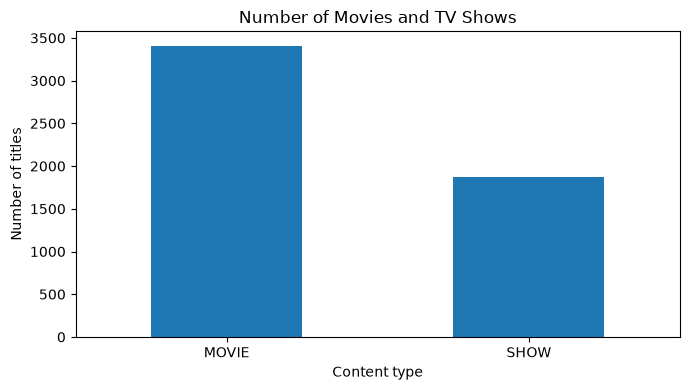

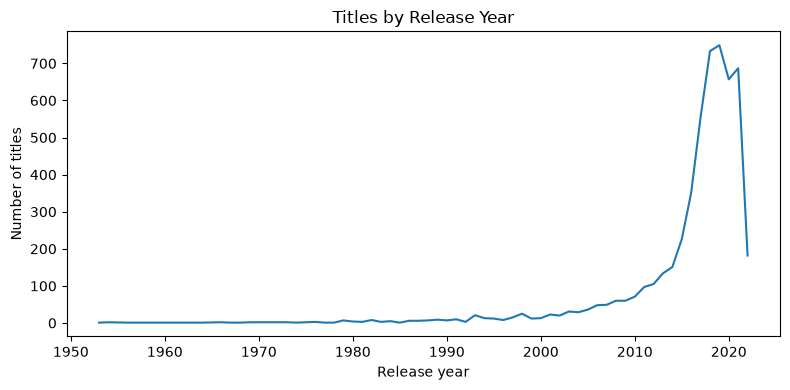

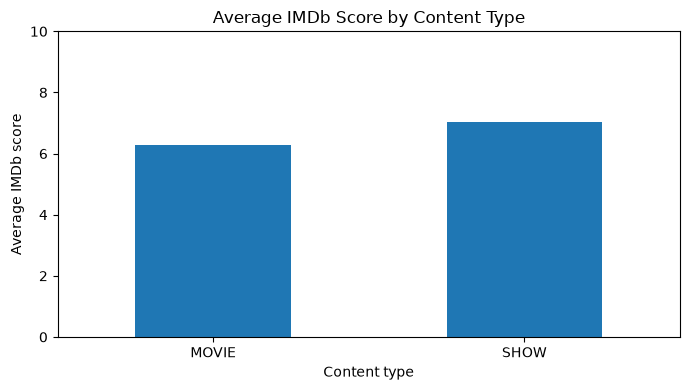

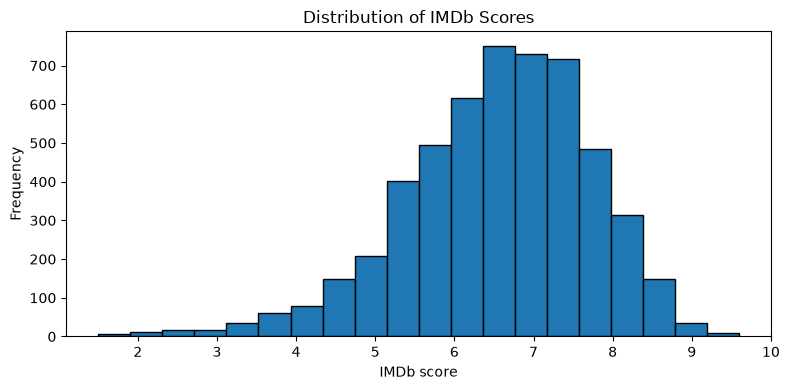

In [6]:
# Chart 1: Movie vs TV show counts
df_clean["type"].value_counts().reindex(["MOVIE", "SHOW"]).plot(kind="bar", figsize=(7,4))
plt.title("Number of Movies and TV Shows")
plt.xlabel("Content type"); plt.ylabel("Number of titles"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

# Chart 2: Titles by release year
df_clean.groupby("release_year").size().sort_index().plot(figsize=(8,4))
plt.title("Titles by Release Year")
plt.xlabel("Release year"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()

# Chart 3: Average IMDb score by content type
df_clean.groupby("type")["imdb_score"].mean().reindex(["MOVIE","SHOW"]).plot(kind="bar", figsize=(7,4))
plt.title("Average IMDb Score by Content Type")
plt.xlabel("Content type"); plt.ylabel("Average IMDb score"); plt.ylim(0,10); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

# Chart 4: IMDb score distribution
df_clean["imdb_score"].plot(kind="hist", bins=20, edgecolor="black", figsize=(8,4))
plt.title("Distribution of IMDb Scores")
plt.xlabel("IMDb score"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()